In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [4]:
#Define Paths & Parameters

train_dir = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\train\wave"
val_dir = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\valid\wave"
test_dir = r"G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\test\wave"
img_size = 224
batch_size = 32
num_classes = 2

In [5]:
#Data Augmentation & Generators

train_gen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    rotation_range=15,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1
).flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical'
)

val_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical'
)

test_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 3640 images belonging to 2 classes.
Found 180 images belonging to 2 classes.
Found 180 images belonging to 2 classes.


In [4]:
#Build MobileNetV2 Model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
output = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# Train all layers
for layer in base_model.layers:
    layer.trainable = True

model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 112, 112, 32)      │             864 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 112, 112, 32)      │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 112, 112, 32)      │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 112, 112, 32)      │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 112, 112, 32)      │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 112, 112, 32)      │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 112, 112, 16)      │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 112, 112, 16)      │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 112, 112, 96)      │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 112, 112, 96)      │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 112, 112, 96)      │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 113, 113, 96)      │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 56, 56, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,226,434 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [5]:
#Train the Model

# Cell 6: Callbacks
checkpoint = ModelCheckpoint("F2_wave_mobilenetv2_finetuned.h5", monitor="val_accuracy", save_best_only=True, verbose=1)
earlystop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

# Cell 7: Train
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=[checkpoint, earlystop]
)

C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6857 - loss: 0.6159
Epoch 1: val_accuracy improved from -inf to 0.53333, saving model to F2_wave_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 385s 3s/step - accuracy: 0.6863 - loss: 0.6149 - val_accuracy: 0.5333 - val_loss: 1.9215
Epoch 2/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8624 - loss: 0.3207
Epoch 2: val_accuracy improved from 0.53333 to 0.62778, saving model to F2_wave_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 341s 3s/step - accuracy: 0.8624 - loss: 0.3208 - val_accuracy: 0.6278 - val_loss: 1.4975
Epoch 3/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8903 - loss: 0.2568
Epoch 3: val_accuracy improved from 0.62778 to 0.67222, saving model to F2_wave_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 337s 3s/step - accuracy: 0.8904 - loss: 0.2568 - val_accuracy: 0.6722 - val_loss: 1.3126
Epoch 4/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9139 - loss: 0.2168
Epoch 4: val_accuracy improved from 0.67222 to 0.71111, saving model to F2_wave_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 338s 3s/step - accuracy: 0.9139 - loss: 0.2167 - val_accuracy: 0.7111 - val_loss: 1.4580
Epoch 5/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9333 - loss: 0.1724
Epoch 5: val_accuracy improved from 0.71111 to 0.84444, saving model to F2_wave_mobilenetv2_finetuned.h5


... (3 outputs left out)

114/114 ━━━━━━━━━━━━━━━━━━━━ 344s 3s/step - accuracy: 0.9695 - loss: 0.0770 - val_accuracy: 0.9222 - val_loss: 0.3162
Epoch 12/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9625 - loss: 0.1106
Epoch 12: val_accuracy improved from 0.92222 to 0.93889, saving model to F2_wave_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 349s 3s/step - accuracy: 0.9626 - loss: 0.1103 - val_accuracy: 0.9389 - val_loss: 0.1912
Epoch 13/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9750 - loss: 0.0709
Epoch 13: val_accuracy did not improve from 0.93889
114/114 ━━━━━━━━━━━━━━━━━━━━ 362s 3s/step - accuracy: 0.9750 - loss: 0.0708 - val_accuracy: 0.8167 - val_loss: 0.8636
Epoch 14/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9758 - loss: 0.0568
Epoch 14: val_accuracy did not improve from 0.93889
114/114 ━━━━━━━━━━━━━━━━━━━━ 358s 3s/step - accuracy: 0.9758 - loss: 0.0568 - val_accuracy: 0.9000 - val_loss: 0.4152
Epoch 15/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9804 - loss: 0.0576
Epoch 15: val_accuracy did not improve from 0.93889
114/114 ━━━━━━━━━━━━━━━━━━━━ 360s 3s/step - accuracy: 0.9804 - loss: 0.0577 - val_accuracy: 0.9222 - val_loss: 0.3048
Epoch 16/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9722 - loss: 0.0655
Epoch 16: val_accuracy impro

114/114 ━━━━━━━━━━━━━━━━━━━━ 347s 3s/step - accuracy: 0.9723 - loss: 0.0655 - val_accuracy: 0.9444 - val_loss: 0.1789
Epoch 17/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9815 - loss: 0.0572
Epoch 17: val_accuracy did not improve from 0.94444
114/114 ━━━━━━━━━━━━━━━━━━━━ 353s 3s/step - accuracy: 0.9815 - loss: 0.0572 - val_accuracy: 0.8944 - val_loss: 0.3310
Epoch 18/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9805 - loss: 0.0452
Epoch 18: val_accuracy improved from 0.94444 to 0.95000, saving model to F2_wave_mobilenetv2_finetuned.h5


114/114 ━━━━━━━━━━━━━━━━━━━━ 342s 3s/step - accuracy: 0.9805 - loss: 0.0451 - val_accuracy: 0.9500 - val_loss: 0.2611
Epoch 19/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9853 - loss: 0.0557
Epoch 19: val_accuracy did not improve from 0.95000
114/114 ━━━━━━━━━━━━━━━━━━━━ 354s 3s/step - accuracy: 0.9853 - loss: 0.0557 - val_accuracy: 0.9167 - val_loss: 0.3771
Epoch 20/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9853 - loss: 0.0404
Epoch 20: val_accuracy did not improve from 0.95000
114/114 ━━━━━━━━━━━━━━━━━━━━ 372s 3s/step - accuracy: 0.9853 - loss: 0.0404 - val_accuracy: 0.9444 - val_loss: 0.2712
Epoch 21/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9888 - loss: 0.0375
Epoch 21: val_accuracy did not improve from 0.95000
114/114 ━━━━━━━━━━━━━━━━━━━━ 362s 3s/step - accuracy: 0.9888 - loss: 0.0376 - val_accuracy: 0.9389 - val_loss: 0.2692
Epoch 21: early stopping
Restoring model weights from the end of the best epoch: 16.


In [7]:
#Save the Best Model 
model.save('F2_wave_mobilenetv2_finetuned.h5')

model.save('F2_wave_mobilenetv2_finetuned.keras')

In [11]:
#Evaluate on the Test Set
loss, acc = model.evaluate(test_gen)
print(f"🧪 Test Accuracy: {acc*100:.2f}%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 624ms/step - accuracy: 0.9270 - loss: 0.2791
🧪 Test Accuracy: 93.89%


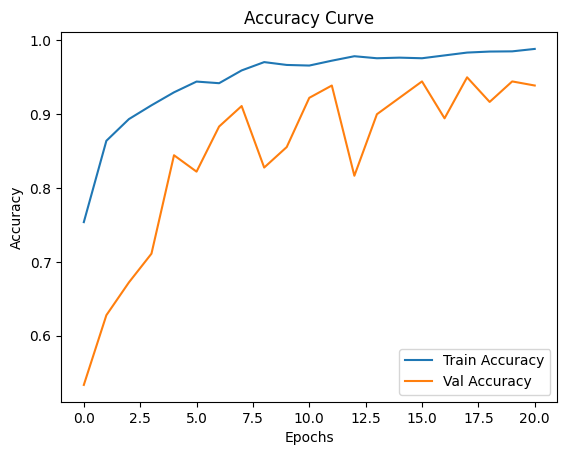

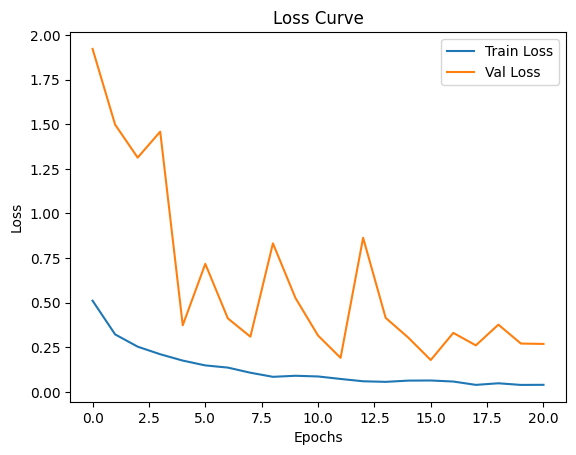

In [12]:
#Plot Accuracy and Loss Curves

import matplotlib.pyplot as plt

# Plot accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [14]:
#Predict on New Images

from tensorflow.keras.models import load_model

model = load_model('F2_wave_mobilenetv2_finetuned.h5')  # or .keras if you saved in keras format

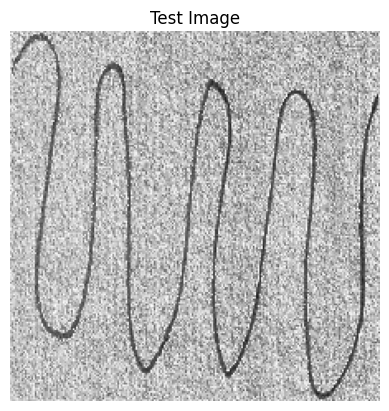

In [15]:
# Load and Preprocess Your Image
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Path to your image
img_path = r'G:\SAIKRISHNA_WORKSPACE\SAI\Major_Projects_2025\IP\VTPIP07\CODE\Drawing-Aware Parkinson’s Disease\test\wave\healthy\Healthy1  (1).jpg'  # replace with actual path

# Load and preprocess
img = image.load_img(img_path, target_size=(224, 224))  # resize to match model input
img_array = image.img_to_array(img) / 255.0              # normalize
img_array = np.expand_dims(img_array, axis=0)            # shape (1, 224, 224, 3)

# Optional: display image
plt.imshow(img)
plt.axis('off')
plt.title("Test Image")
plt.show()

In [16]:
class_names = ['healthy', 'parkinson']  # adjust if needed

# Predict
prediction = model.predict(img_array)
predicted_class = class_names[np.argmax(prediction)]

# Confidence
confidence = np.max(prediction) * 100

print(f"🧠 Predicted Class: {predicted_class}")
print(f"📊 Confidence: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
🧠 Predicted Class: healthy
📊 Confidence: 100.00%


C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step 
 Classification Report:
              precision    recall  f1-score   support

     healthy       0.49      1.00      0.66        89
   parkinson       0.00      0.00      0.00        91

    accuracy                           0.49       180
   macro avg       0.25      0.50      0.33       180
weighted avg       0.24      0.49      0.33       180



C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Python1\anaconda3\envs\vtpml04_2\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le

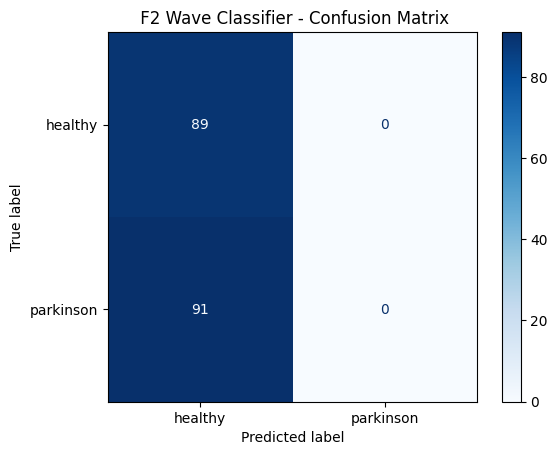

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

#  Load your trained F2 wave model
from tensorflow.keras.models import load_model
model = load_model("F2_wave_mobilenetv2_finetuned.h5")  # adjust if your filename differs

# Predict on test set
y_pred_probs = model.predict(test_gen)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes  # True labels from test generator

#  Get class names from the generator
class_names = list(test_gen.class_indices.keys())

# Classification Report
print(" Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

#  Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')
plt.title(" F2 Wave Classifier - Confusion Matrix")
plt.show()